# 🌦️ Addis Weather Analyst
### Week 1 Practical · AI/ML AWS AASTU Cohort

One small project, from **raw API data** all the way to **an AI agent** — using only what you learned in Week 1, plus a few new libraries.

**How to use this notebook:** run the cells from top to bottom (`Shift + Enter`). Read the short text above each cell first.

| Phase | What we do | Week 1 idea it uses | Hat you wear |
|---|---|---|---|
| 0 | Get the project from GitHub | Git clone, `pip install -r requirements.txt` | — |
| 1 | Call a weather API | `requests`, JSON, status codes | — |
| 2 | Clean & analyze the data | functions, pandas, NumPy | — |
| 3 | Train a small ML model | scikit-learn | 🧪 **ML Engineer** |
| 4 | Ask an LLM to write a report | API + API keys | 🛠️ **AI Engineer** |
| 5 | Let the LLM choose which code to run | functions as tools | 🛠️ **AI Engineer** |
| 6 | Save everything back to GitHub | Git/GitHub workflow | — |

**Where this sits on the evolution ladder:**
Classical ML (Phase 3) → Deep learning → Transformers → Generative AI (Phase 4) → Agents (Phase 5).
We *train* the classical model ourselves, but for the later rungs we *use* huge pre-trained models through an API — that is exactly the difference between the two roles.

## Phase 0 · Get the project into Colab  
Colab opened *only the notebook* from GitHub. The rest of the project (data folder, `requirements.txt`) lives in the repo, so we **clone** it and install the packages from `requirements.txt`.

In [1]:
import os, sys

GITHUB_USER = "Robel-ermiyas"
REPO = "addis-weather-analyst"

if "google.colab" in sys.modules:                      # running in Colab
    assert "YOUR-" not in GITHUB_USER, "👆 Put the GitHub username in GITHUB_USER first"
    if not os.path.isdir(REPO):
        !git clone https://github.com/{GITHUB_USER}/{REPO}.git
    %cd {REPO}
    !pip install -q -r requirements.txt
else:                                                  # running on your own laptop (inside your venv)
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")

print("📂 Working folder:", os.getcwd())
print("📄 Files here:", sorted(os.listdir(".")))

Cloning into 'addis-weather-analyst'...
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 14 (delta 0), reused 14 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (14/14), 20.47 KiB | 5.12 MiB/s, done.
/content/addis-weather-analyst
📂 Working folder: /content/addis-weather-analyst
📄 Files here: ['.git', '.gitignore', 'README.md', 'bonus', 'data', 'notebooks', 'requirements.txt']


In [2]:
import json, time
from datetime import date, timedelta

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("requests", requests.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

requests 2.32.4 | numpy 2.1.3 | pandas 2.2.3


## Phase 1 · Call a weather API
An **API** is just a URL. You send a request with some parameters, and the server sends back **JSON**.

We use [Open-Meteo](https://open-meteo.com): free, **no API key**, real weather data. Two calls:
1. **Geocoding** — city name → latitude/longitude
2. **Archive** — latitude/longitude + dates → daily weather

Notice the three habits from the lecture: `timeout`, **check `status_code`**, then `.json()`.

In [3]:
GEOCODE_URL = "https://geocoding-api.open-meteo.com/v1/search"
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"


def get_coordinates(city):
    """Turn a city name into (name, latitude, longitude, country). Returns None if not found."""
    r = requests.get(
        GEOCODE_URL,
        params={"name": city, "count": 1, "language": "en", "format": "json"},
        timeout=15,
    )
    if r.status_code != 200:
        raise RuntimeError(f"Geocoding error {r.status_code}: {r.text[:200]}")
    results = r.json().get("results")
    if not results:
        return None
    top = results[0]
    return top["name"], top["latitude"], top["longitude"], top.get("country", "")


def fetch_weather(lat, lon, start, end):
    """Download daily weather between two dates (YYYY-MM-DD). Returns the raw JSON as a dict."""
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max",
        "timezone": "auto",
    }
    r = requests.get(ARCHIVE_URL, params=params, timeout=30)
    if r.status_code != 200:                      # always check before trusting the data!
        raise RuntimeError(f"Weather API error {r.status_code}: {r.text[:200]}")
    return r.json()


print("✅ Functions defined: get_coordinates(), fetch_weather()")

✅ Functions defined: get_coordinates(), fetch_weather()


In [4]:
# The archive lags a few days behind "today", so we stop one week ago. Two years of data.
end = date.today() - timedelta(days=7)
start = end - timedelta(days=730)

try:
    place = get_coordinates("Addis Ababa")
    print("📍 Found:", place)
    _, lat, lon, _ = place
    raw = fetch_weather(lat, lon, start.isoformat(), end.isoformat())
    SOURCE = "live Open-Meteo API ✅"
except Exception as e:
    # Safety net for bad Wi-Fi: use the SYNTHETIC sample file that ships with the repo
    print("⚠️ Live API failed:", e)
    raw = json.load(open("data/sample_response.json"))
    SOURCE = "OFFLINE SAMPLE (synthetic data!) ⚠️"

print("\nData source:", SOURCE)
print("Top-level keys:", list(raw.keys()))
print("Days returned :", len(raw["daily"]["time"]))
print("First 3 max temperatures:", raw["daily"]["temperature_2m_max"][:3])

📍 Found: ('Addis Ababa', 9.02497, 38.74689, 'Ethiopia')

Data source: live Open-Meteo API ✅
Top-level keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']
Days returned : 731
First 3 max temperatures: [18.4, 17.7, 16.7]


**💥 Break it on purpose.** Latitude can only be between -90 and 90. What does the API say when we send nonsense?
This is how you learn status codes — by seeing real errors.

In [5]:
try:
    bad = requests.get(
        ARCHIVE_URL,
        params={"latitude": 999, "longitude": 38.7, "start_date": "2025-01-01",
                "end_date": "2025-01-05", "daily": "temperature_2m_max"},
        timeout=15,
    )
    print("Status code:", bad.status_code)     # 4xx = *our* mistake, 5xx = *their* mistake
    print("Server says:", bad.text[:200])
except requests.RequestException as e:
    print("No internet / request failed:", e)

Status code: 400
Server says: {"error":true,"reason":"Latitude must be in range of -90 to 90°. Given: 999.0."}


## Phase 2 · Clean & analyze
Real data is never perfect. Plan: JSON → **pandas** table → fix problems with a **function** → analyze with **NumPy**.

In [6]:
df_raw = pd.DataFrame(raw["daily"])
display(df_raw.head())
print("Missing values per column (BEFORE cleaning):")
print(df_raw.isna().sum().to_string())

,time,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max
0,2024-10-11,18.4,8.9,21.0,9.2
1,2024-10-12,17.7,11.4,9.3,12.3
2,2024-10-13,16.7,9.3,16.0,9.8
3,2024-10-14,18.7,8.4,4.3,10.1
4,2024-10-15,19.3,8.2,0.4,16.2


Missing values per column (BEFORE cleaning):
time                  0
temperature_2m_max    0
temperature_2m_min    0
precipitation_sum     0
wind_speed_10m_max    0


In [7]:
def clean_weather(raw):
    """Raw API JSON -> tidy DataFrame with friendly column names and no missing values."""
    df = pd.DataFrame(raw["daily"]).rename(columns={
        "time": "date",
        "temperature_2m_max": "temp_max",
        "temperature_2m_min": "temp_min",
        "precipitation_sum": "rain_mm",
        "wind_speed_10m_max": "wind_max",
    })
    df["date"] = pd.to_datetime(df["date"])                      # text -> real dates
    num_cols = ["temp_max", "temp_min", "wind_max"]
    df[num_cols] = df[num_cols].interpolate(limit_direction="both")   # fill gaps from neighbours
    df["rain_mm"] = df["rain_mm"].fillna(0)                      # no value -> assume no rain
    df["temp_mean"] = (df["temp_max"] + df["temp_min"]) / 2
    df["month"] = df["date"].dt.month
    return df


df = clean_weather(raw)
print("Missing values AFTER cleaning:", int(df.isna().sum().sum()))
display(df.head())
display(df.describe().round(1))

Missing values AFTER cleaning: 0


,date,temp_max,temp_min,rain_mm,wind_max,temp_mean,month
0,2024-10-11,18.4,8.9,21.0,9.2,13.65,10
1,2024-10-12,17.7,11.4,9.3,12.3,14.55,10
2,2024-10-13,16.7,9.3,16.0,9.8,13.00,10
3,2024-10-14,18.7,8.4,4.3,10.1,13.55,10
4,2024-10-15,19.3,8.2,0.4,16.2,13.75,10


,date,temp_max,temp_min,rain_mm,wind_max,temp_mean,month
count,731,731.0,731.0,731.0,731.0,731.0,731.0
mean,2025-10-11 00:00:00,21.8,9.5,2.9,14.3,15.7,6.5
min,2024-10-11 00:00:00,16.7,4.0,0.0,6.6,12.4,1.0
25%,2025-04-11 12:00:00,20.3,8.5,0.0,11.5,14.6,4.0
50%,2025-10-11 00:00:00,21.6,9.7,0.2,14.2,15.4,7.0
75%,2026-04-11 12:00:00,23.2,10.7,3.9,16.7,16.5,10.0
max,2026-10-11 00:00:00,26.9,14.4,27.7,24.9,20.2,12.0
std,NaN,2.1,1.7,4.9,3.4,1.4,3.5


### NumPy: fast math on whole arrays
A pandas column can become a NumPy array. Then **no loops** — the operation is applied to every day at once (vectorization).

In [8]:
temps = df["temp_max"].to_numpy()
print(type(temps), "| shape:", temps.shape, "| dtype:", temps.dtype)

avg_7 = np.convolve(temps, np.ones(7) / 7, mode="valid")     # 7-day moving average
z = (temps - temps.mean()) / temps.std()                     # "how many std-devs from normal is this day?"
hot_days = np.where(z > 2)[0]                                # positions of unusually hot days

print(f"Average daily max : {temps.mean():.1f} °C")
print(f"Hottest day       : {temps.max():.1f} °C on {df['date'].iloc[temps.argmax()].date()}")
print(f"Unusually hot days: {len(hot_days)}")

<class 'numpy.ndarray'> | shape: (731,) | dtype: float64
Average daily max : 21.8 °C
Hottest day       : 26.9 °C on 2025-04-11
Unusually hot days: 22


In [9]:
# Why NumPy? Same job, two ways, 2 million numbers.
big = np.random.rand(2_000_000)

t0 = time.perf_counter()
slow = [x * 2 + 1 for x in big]            # Python loop
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
fast = big * 2 + 1                         # NumPy, vectorized
t_np = time.perf_counter() - t0

print(f"Python loop: {t_loop:.3f}s   |   NumPy: {t_np:.4f}s   |   ~{t_loop / max(t_np, 1e-9):.0f}x faster")

Python loop: 0.445s   |   NumPy: 0.0160s   |   ~28x faster


In [10]:
# 📝 TODO 1 (2 min): On how many days did it rain MORE than 10 mm?
# Hint: a comparison like  rain > 10  gives True/False for every day. .sum() counts the Trues.
rain = df["rain_mm"].to_numpy()

heavy_rain_days = (rain > 10).sum()     # <- replace None with your NumPy code

if heavy_rain_days is None:
    print("✏️ Your turn! Replace None with your code and run this cell again.")
else:
    print(f"🌧️ Heavy-rain days: {int(heavy_rain_days)} out of {len(rain)}")

🌧️ Heavy-rain days: 85 out of 731


<details><summary>💡 Stuck? Click for the solution</summary>

```python
heavy_rain_days = (rain > 10).sum()
```
</details>

### Always look at your data before modeling

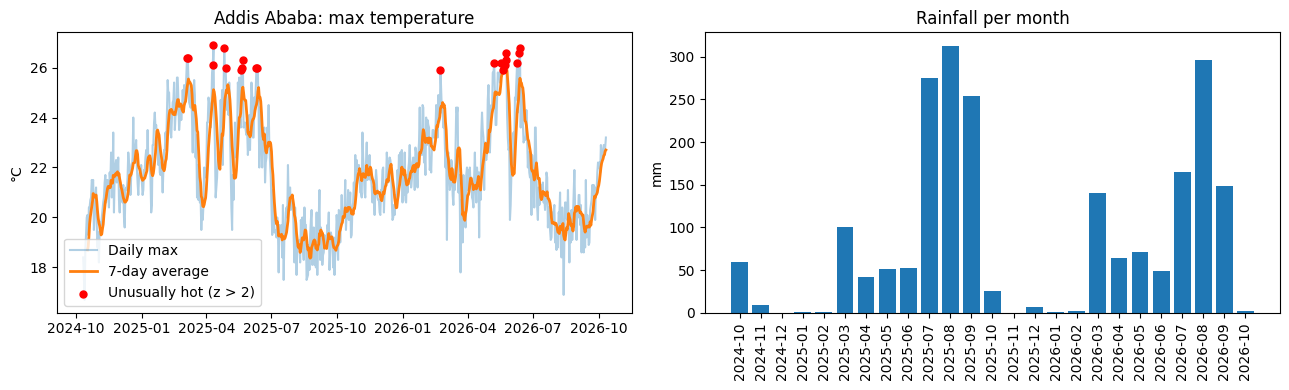

🌧️ Rainiest month: 2025-08 (313 mm)


In [11]:
tag = "  (SYNTHETIC sample)" if "OFFLINE" in SOURCE else ""
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(df["date"], temps, alpha=0.35, label="Daily max")
ax[0].plot(df["date"].iloc[6:], avg_7, linewidth=2, label="7-day average")
ax[0].scatter(df["date"].iloc[hot_days], temps[hot_days], color="red", s=25, zorder=3, label="Unusually hot (z > 2)")
ax[0].set_title("Addis Ababa: max temperature" + tag)
ax[0].set_ylabel("°C")
ax[0].legend()

monthly = df.groupby(df["date"].dt.to_period("M"))["rain_mm"].sum()
ax[1].bar(monthly.index.astype(str), monthly.values)
ax[1].set_title("Rainfall per month" + tag)
ax[1].set_ylabel("mm")
ax[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()
print("🌧️ Rainiest month:", monthly.idxmax(), f"({monthly.max():.0f} mm)")

## Phase 3 · Classical ML    🧪 *ML Engineer hat*
**Question:** given *today's* weather, will it rain *tomorrow*?

The ML engineer's loop: **features → split → train → evaluate**. We use a Random Forest from scikit-learn — a classical ML model, no deep learning, trains in a second.

Two things to notice:
- We split **by time** (train on the past, test on the most recent 20%). A random split would let the model "peek" at the future.
- We compare against a **baseline** ("always guess the most common answer"). Accuracy alone can fool you.

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

ml = df.copy()
ml["rain_tomorrow"] = (ml["rain_mm"].shift(-1) > 1).astype(int)   # 1 = more than 1 mm tomorrow
ml = ml.iloc[:-1]                                                 # last day has no "tomorrow"

FEATURES = ["temp_max", "temp_min", "rain_mm", "wind_max", "month"]
X, y = ml[FEATURES], ml["rain_tomorrow"]

split = int(len(ml) * 0.8)                                        # first 80% = train, last 20% = test
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print(f"Train: {len(X_train)} days | Test: {len(X_test)} days | Rainy days in test: {y_test.mean():.0%}")

Train: 584 days | Test: 146 days | Rainy days in test: 67%


In [15]:
N_TREES = 10      # 📝 TODO 2 (1 min): change these two numbers, re-run, and watch the accuracy.
MAX_DEPTH = 3    #    Try N_TREES = 10 or 300, and MAX_DEPTH = 3 or 10.

model = RandomForestClassifier(n_estimators=N_TREES, max_depth=MAX_DEPTH, random_state=42)
model.fit(X_train, y_train)                       # <- this one line is "training"

pred = model.predict(X_test)
acc = accuracy_score(y_test, pred)
baseline = max(y_test.mean(), 1 - y_test.mean())

print(f"Model accuracy    : {acc:.0%}")
print(f"Baseline accuracy : {baseline:.0%}   (always guess the most common answer)")
print(f"Of days it predicted rain, {precision_score(y_test, pred, zero_division=0):.0%} really had rain (precision)")
print(f"Of days that really had rain, it caught {recall_score(y_test, pred, zero_division=0):.0%} (recall)")

print("\nWhat the model pays attention to:")
print(pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False).round(2).to_string())

Model accuracy    : 84%
Baseline accuracy : 67%   (always guess the most common answer)
Of days it predicted rain, 90% really had rain (precision)
Of days that really had rain, it caught 86% (recall)

What the model pays attention to:
rain_mm     0.51
temp_max    0.19
wind_max    0.17
month       0.10
temp_min    0.03


## Phase 4 · Generative AI via an API  🛠️ *AI Engineer hat*
We just *trained* a model. Now we *use* a huge pre-trained one (Google Gemini) through an API — the AI engineer's daily job.

🔑 **API keys are passwords.** Never paste them into code you push to GitHub. In Colab, click the **🔑 Secrets** icon in the left sidebar → add a secret named `GEMINI_API_KEY` → turn on *Notebook access*. Get a free key at [Google AI Studio](https://aistudio.google.com/apikey).

> No key yet? No problem — the cells below skip themselves and you can watch the demo.

In [17]:
# Load the key from Colab Secrets (or from an environment variable if you run locally)
API_KEY = None
try:
    from google.colab import userdata
    API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    API_KEY = os.environ.get("GEMINI_API_KEY")

HAVE_LLM = bool(API_KEY)

# Model names change often. If this one errors, copy a current Flash model name from
# https://ai.google.dev/gemini-api/docs/models  (for example "gemini-3.8-flash").
MODEL = "gemini-flash-latest"

if HAVE_LLM:
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=API_KEY)
    print("✅ Gemini client ready | model:", MODEL)
else:
    print("⏭️ No GEMINI_API_KEY found — LLM cells will be skipped (follow the instructor's demo).")


def call_with_retry(fn, tries=3, wait=15):
    """Free tiers have rate limits. If a call fails, wait a bit and try again."""
    for attempt in range(1, tries + 1):
        try:
            return fn()
        except Exception as e:
            print(f"⚠️ Attempt {attempt}/{tries} failed: {str(e)[:150]}")
            if attempt == tries:
                raise
            time.sleep(wait)

✅ Gemini client ready | model: gemini-flash-latest


In [18]:
def ask_llm(prompt, system="You are a friendly assistant for university students in Ethiopia."):
    resp = call_with_retry(lambda: client.models.generate_content(
        model=MODEL,
        contents=prompt,
        config=types.GenerateContentConfig(system_instruction=system, temperature=0.3),
    ))
    return resp.text or "(no text returned)"


# An LLM can WRITE well but it should not do the math. We compute facts with NumPy/pandas, then hand them over.
facts = {
    "city": "Addis Ababa",
    "period": f"{df['date'].min().date()} to {df['date'].max().date()}",
    "average_max_temp_c": round(float(df["temp_max"].mean()), 1),
    "hottest_day_c": round(float(df["temp_max"].max()), 1),
    "total_rain_mm": round(float(df["rain_mm"].sum())),
    "rainiest_month": str(monthly.idxmax()),
    "rain_model_accuracy": round(float(acc), 2),
    "rain_model_baseline": round(float(baseline), 2),
}
if "OFFLINE" in SOURCE:
    facts["note"] = "These numbers come from SYNTHETIC sample data. Say so in the report."

if HAVE_LLM:
    report = ask_llm(
        "Here are facts computed with NumPy and pandas:\n"
        + json.dumps(facts, indent=2)
        + "\n\nWrite a friendly 3-sentence weather report for students. Use ONLY these numbers."
    )
    print(report)
else:
    print("⏭️ Skipped (no API key). Facts that would be sent to the LLM:")
    print(json.dumps(facts, indent=2))

Hello students in Addis Ababa, for the period from 2024-10-11 to 2026-10-11, the average maximum temperature is a pleasant 21.8 °C, with the hottest day peaking at 26.9 °C. Don't forget your umbrellas around campus because total rain will reach 2127 mm, with 2025-08 marking the rainiest month. You can confidently plan your study days since our rain model achieved an accuracy of 0.84, well above the 0.67 baseline!


## Phase 5 · Mini agent  🛠️ *AI Engineer hat*
So far *we* decided what code to run. In an **agent**, the **LLM decides**.

```
 Your question ──► LLM ──► "I need get_weather_summary('Mekelle', 14)"
                    ▲                    │
                    │                    ▼
              final answer ◄──── YOUR code runs the function
```

1. We describe our Python functions to the model (the **tools**: name, arguments, docstring).
2. The model replies with *which tool to call and with what arguments* — it never runs code itself.
3. The SDK runs our function and sends the result back.
4. The model writes the final answer.

The functions we wrote in Phases 1–3 become the agent's tools. Watch for the `🔧 Tool called` lines — that is the LLM making a decision.

In [19]:
def get_weather_summary(city: str, days: int = 30) -> dict:
    """Get a summary of the recent daily weather for any city in the world.

    Args:
        city: City name, for example "Bahir Dar" or "Mekelle".
        days: How many past days to summarise, from 1 to 90. Data lags a few days behind today.

    Returns:
        A dict with average max/min temperature, total rainfall, number of rainy days and the hottest day.
    """
    print(f"   🔧 Tool called: get_weather_summary(city={city!r}, days={days})")
    try:
        days = max(1, min(int(days), 90))
        place = get_coordinates(city)
        if place is None:
            return {"error": f"Could not find a city called {city!r}"}
        name, lat, lon, country = place
        end_d = date.today() - timedelta(days=7)
        start_d = end_d - timedelta(days=days - 1)
        c = clean_weather(fetch_weather(lat, lon, start_d.isoformat(), end_d.isoformat()))
        tmax, rain_c = c["temp_max"].to_numpy(), c["rain_mm"].to_numpy()
        hottest = int(np.argmax(tmax))
        return {
            "city": f"{name}, {country}",
            "period": f"{c['date'].iloc[0].date()} to {c['date'].iloc[-1].date()}",
            "avg_max_temp_c": round(float(tmax.mean()), 1),
            "avg_min_temp_c": round(float(c["temp_min"].mean()), 1),
            "total_rain_mm": round(float(rain_c.sum()), 1),
            "rainy_days": int((rain_c > 1).sum()),
            "hottest_day": str(c["date"].iloc[hottest].date()),
            "hottest_day_temp_c": round(float(tmax[hottest]), 1),
        }
    except Exception as e:                      # a tool should never crash the agent: return the error instead
        return {"error": f"Weather lookup failed: {e}"}


def predict_rain_tomorrow() -> dict:
    """Predict whether it will rain the day after the latest day in our Addis Ababa dataset,
    using the machine-learning model trained earlier in this notebook. Only works for Addis Ababa.
    """
    print("   🔧 Tool called: predict_rain_tomorrow()")
    last = df.iloc[[-1]]
    prob = float(model.predict_proba(last[FEATURES])[0][1])
    return {
        "city": "Addis Ababa",
        "based_on_date": str(last["date"].iloc[0].date()),
        "rain_probability": round(prob, 2),
        "prediction": "rain" if prob >= 0.5 else "no rain",
    }


AGENT_SYSTEM = (
    "You are a helpful weather assistant for students in Ethiopia. "
    "Use the provided tools to get data. Never invent numbers. "
    "Mention the dates your data covers. Keep answers under 4 sentences."
)


def ask_agent(question):
    print(f"🧑 Question: {question}")
    chat = client.chats.create(                                     # a chat runs the tool-calling loop for us
        model=MODEL,
        config=types.GenerateContentConfig(
            system_instruction=AGENT_SYSTEM,
            tools=[get_weather_summary, predict_rain_tomorrow],     # <- plain Python functions!
            automatic_function_calling=types.AutomaticFunctionCallingConfig(maximum_remote_calls=5),
        ),
    )
    resp = call_with_retry(lambda: chat.send_message(question))
    print("🤖 Answer:", resp.text or "(no text returned)")
    print()


print("✅ Two tools ready: get_weather_summary(), predict_rain_tomorrow()")

✅ Two tools ready: get_weather_summary(), predict_rain_tomorrow()


**First, the problem.** Ask the model the same kind of question *without* tools:

In [20]:
if HAVE_LLM:
    resp = call_with_retry(lambda: client.models.generate_content(
        model=MODEL, contents="How hot and rainy was it in Bahir Dar over the last 2 weeks? Give exact numbers."))
    print(resp.text)
else:
    print("⏭️ Skipped (no API key).")

I do not have access to real-time or recent live meteorological data, so I cannot provide the exact daily temperatures and rainfall measurements for Bahir Dar over the specific last two weeks.

To find exact, day-by-day historical measurements (high/low temperatures and precipitation in mm), you can check:

1. **Weather Underground's History Tab** (search for Bahir Dar / ICAO code: **HABD**).
2. **Open-Meteo Historical Weather API** (open-meteo.com), which provides free access to past daily weather records by entering Bahir Dar's coordinates (11.59° N, 37.39° E).
3. **The Ethiopian Meteorology Institute (EMI)** official portal. 

---

### General Climate Reference for Bahir Dar:
* **Dry Season (October – May):** Days are typically warm and sunny (daily highs around **27°C to 31°C / 80°F to 88°F**, lows around **10°C to 14°C / 50°F to 57°F**), with rainfall typically close to **0 to 5 mm** across a two-week span.
* **Main Rainy Season (*Kiremt*, June – September):** Highs drop slightly 

It cannot know — it has no access to live data (it may even guess!). **Now give it tools:**

In [21]:
if HAVE_LLM:
    ask_agent("How was the weather in Bahir Dar over the last 14 days?")
    ask_agent("Should I carry an umbrella in Addis Ababa tomorrow?")
else:
    print("⏭️ Skipped (no API key).")

🧑 Question: How was the weather in Bahir Dar over the last 14 days?
   🔧 Tool called: get_weather_summary(city='Bahir Dar', days=14)
🤖 Answer: For the period covering September 28 to October 11, 2026, Bahir Dar had an average maximum temperature of 25.4°C and an average minimum of 14.3°C. The hottest day was October 2, reaching 26.3°C. Over these 14 days, there were 3 rainy days with a total rainfall of 25.6 mm.

🧑 Question: Should I carry an umbrella in Addis Ababa tomorrow?
   🔧 Tool called: predict_rain_tomorrow()
🤖 Answer: Based on weather data up to October 11, 2026, the model predicts no rain for Addis Ababa tomorrow (October 12, 2026) with only a 6% chance of precipitation. Therefore, you likely do not need to carry an umbrella.



**Bonus** — a question that needs *two* tool calls. Nobody told the model to call the function twice; it worked that out:

In [22]:
if HAVE_LLM:
    ask_agent("Compare the last 30 days of weather in Addis Ababa and Mekelle. Which city was wetter?")
else:
    print("⏭️ Skipped (no API key).")

🧑 Question: Compare the last 30 days of weather in Addis Ababa and Mekelle. Which city was wetter?
   🔧 Tool called: get_weather_summary(city='Addis Ababa', days=30)
   🔧 Tool called: get_weather_summary(city='Mekelle', days=30)
   🔧 Tool called: get_weather_summary(city="Mek'ele", days=30)
   🔧 Tool called: get_weather_summary(city='Meqele', days=30)
🤖 Answer: From September 12, 2026, to October 11, 2026, Addis Ababa received 64.7 mm of rainfall over 12 rainy days, with average daily temperatures ranging from 9.9°C to 21.2°C. During the same period, Mekelle (Mek'ele) recorded 15.6 mm of rain across 6 rainy days, with warmer average temperatures between 14.1°C and 26.1°C. Therefore, Addis Ababa was the wetter city.



## Phase 6 · Save your work to GitHub
First save the cleaned data, and "freeze" the exact package versions we used (slide 13).

In [23]:
os.makedirs("data", exist_ok=True)
df.to_csv("data/addis_weather_clean.csv", index=False)
print("💾 Saved data/addis_weather_clean.csv with", len(df), "rows")

!pip freeze | grep -iE "^(numpy|pandas|requests|matplotlib|scikit-learn|google-genai)=="

💾 Saved data/addis_weather_clean.csv with 731 rows
google-genai==2.12.1
matplotlib==3.10.0
numpy==2.1.3
pandas==2.2.3
requests==2.32.4
scikit-learn==1.6.1


### Push this notebook to *your own* GitHub repo
1. On GitHub, create a **new empty repo** (e.g. `week1-weather-project`).
2. In Colab: **File → Save a copy in GitHub**.
3. The first time, allow Colab to access GitHub in the pop-up.
4. Pick your repo, write a commit message such as `Add Week 1 weather notebook`, click **OK**.
5. Open your repo on GitHub — your notebook is there! Use **Add file → Upload files** to also add a `README.md` and `requirements.txt`.

Your Week 1 deliverable needs: **notebook + README + requirements.txt + real commit history** (commit more than once as you improve it).

---
## 🏁 Challenge (homework)
Pick **one**:
1. Run the whole project for another city (Bahir Dar, Hawassa, Mekelle…) and compare the rain model's accuracy.
2. Add a **third tool** to the agent, for example `get_hottest_day(city)`, and ask a question that needs it.
3. Use the **GitHub API** to analyze your own repos (how many? which languages?).

**Stretch:** look at the `bonus/` folder in the repo — the same project as a web app (Gradio) and a `Dockerfile`.